In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mukeshkumar95/canadian-health-survey-on-seniors-20192020/pumf_chss.csv


The purpose of this project is to explore, understand, and validate the dataset before applying
any machine learning models.

## 1. Dataset overview:
Load the dataset to inspect its size, review column names and data types, identify target
and input feature

Dataset link - https://www150.statcan.gc.ca/n1/en/catalogue/13250010

In [2]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#loading dataset

raw=pd.read_csv("/kaggle/input/datasets/mukeshkumar95/canadian-health-survey-on-seniors-20192020/pumf_chss.csv")

In [4]:
#checking the first 5 rows of the data to get a glimpse of data
raw.head()

,ADM_RNO2,VERDATE,REFPER,GEOGPRV,DHH_SEX,DHHGMS,DHHDGHSZ,ADM_PRX,DHHGAGE,DOMAC,...,DOC3ADH,ADH_20,ADH_25,DOC3HTU,HTU_01,HTU_05,HTU_10,HTU_15,HTU_20,WTS_CM
0,100007,20240531,2019-2020,35.0,1.0,1.0,2.0,2.0,5.0,1.0,...,1.0,6.0,2.0,1.0,2.0,6.0,6.0,2.0,6.0,82.69
1,100050,20240531,2019-2020,11.0,1.0,1.0,2.0,2.0,5.0,1.0,...,1.0,6.0,2.0,1.0,1.0,1.0,2.0,2.0,6.0,27.15
2,100055,20240531,2019-2020,48.0,2.0,2.0,1.0,2.0,5.0,1.0,...,1.0,6.0,2.0,1.0,1.0,2.0,2.0,2.0,6.0,53.40
3,100061,20240531,2019-2020,47.0,1.0,1.0,2.0,2.0,5.0,1.0,...,1.0,6.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,162.00
4,100079,20240531,2019-2020,10.0,1.0,2.0,1.0,2.0,5.0,1.0,...,1.0,6.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,12.41


In [5]:
#Checking dataset dimensions
print("This dataset contains",raw.shape[0],"Rows and",raw.shape[1], "Columns")

This dataset contains 41550 Rows and 727 Columns


In [6]:
#Checking all columns
''' 
for column in raw.columns:
    print(column)
'''
#checking the first 30 columns after assessing all columns using above code
column_names = pd.DataFrame(raw.columns, columns=["Column Name"])
column_names.head(30)

,Column Name
0,ADM_RNO2
1,VERDATE
2,REFPER
3,GEOGPRV
4,DHH_SEX
5,DHHGMS
6,DHHDGHSZ
7,ADM_PRX
8,DHHGAGE
9,DOMAC


In [7]:
#Selecting our study population.
#code 1 from SDCDVIMM column includes immigrants and non-permanent residents.
immigrant_df = raw[raw["SDCDVIMM"] == 1].copy()

print("Respondents in our study:", len(immigrant_df))

Respondents in our study: 5871


In [8]:
# As per our research on this dataset and our previous assignment, we have decided to choose LONDVSCR variable as our target variable.
#We are checking the target and immigration variables
raw[["LONDVSCR", "SDCDVIMM"]].head(10)

,LONDVSCR,SDCDVIMM
0,3.0,1.0
1,3.0,2.0
2,3.0,2.0
3,3.0,2.0
4,3.0,2.0
5,3.0,2.0
6,3.0,2.0
7,3.0,2.0
8,99.0,2.0
9,9.0,2.0


In [9]:
#checking unique values in the target variable
print(raw["LONDVSCR"].value_counts(dropna=False).sort_index())

#checking unique values in immigration variable
print(raw["SDCDVIMM"].value_counts(dropna=False).sort_index())

LONDVSCR
3.0     25015
4.0      5891
5.0      3526
6.0      2354
7.0      1016
8.0       450
9.0       619
99.0     2679
Name: count, dtype: int64
SDCDVIMM
1.0     5871
2.0    35479
9.0      200
Name: count, dtype: int64


From above result, we can see that the scores, range from 3.0 to 9.0 and a seperate 99.0. We will be removing that data (99.0) because that score means unavailable as per data dictionary. As per our group assignment submission, we decided the scores[0-4] as 0 and [5-9] as 1 for our classification task.

In [10]:
# we are only keeping the respondents with valid loneliness scores and immigrant status
immigrant_df = raw[
    raw["LONDVSCR"].between(3, 9) &
    (raw["SDCDVIMM"] == 1)].copy()

print("Immigrant respondents with valid loneliness scores:", len(immigrant_df))
print(immigrant_df["LONDVSCR"].value_counts().sort_index())

Immigrant respondents with valid loneliness scores: 5326
LONDVSCR
3.0    3483
4.0     704
5.0     490
6.0     353
7.0     142
8.0      63
9.0      91
Name: count, dtype: int64


After going through the data dictionary of this dataset, we have decided to the choose the below colums as input features for our task. We will rename the code names with the proper names taken from from the data dictionary for better understanding for our group to perform EDA and model training.

We, may add more columns in the future depending on how the model performs.

In [11]:
column_names = {
    # Supporting fields — not model predictors
    "ADM_RNO2": "respondent_id",
    "SDCDVIMM": "immigrant_or_nonpermanent_resident_status",
    "ADM_PRX": "health_interview_completed_by_proxy",
    "WTS_CM": "survey_weight",

    # Source used to create the classification target
    "LONDVSCR": "loneliness_score",

    # Demographic and socioeconomic characteristics
    "DHH_SEX": "sex_at_birth",
    "DHHGMS": "marital_status_group",
    "DHHDGHSZ": "household_size_group",
    "GEOGPRV": "province",
    "EHG2DVH3": "highest_household_education",
    "INCDGHH": "household_income_group",

    # General and functional health
    "GEN_005": "perceived_general_health",
    "HUIDGHSI": "functional_health_group",
    "HUIDGPAD": "usual_pain_or_discomfort",

    # Chronic conditions and falls
    "CCC_035": "sleep_apnea",
    "CCC_065": "high_blood_pressure",
    "CCC_075": "high_cholesterol_or_lipids",
    "CCC_095": "diabetes",
    "CCC_185": "chronic_fatigue_syndrome",
    "CCCDGRSP": "respiratory_condition_group",
    "CCCDGSKL": "musculoskeletal_condition_group",
    "CCCDGCAR": "cardiovascular_condition_group",
    "FAL_01": "any_falls_past_12_months",

    # Social circumstances
    "GEN_030": "sense_of_community_belonging",
    "SPB_09": "wanted_more_social_participation",

    # Transportation, care, and accessibility
    "TRA_04": "usual_transportation_mode",
    "ADH_25": "self_reported_unmet_home_adaptations",
    "PHC_005": "usual_minor_care_place",
    "CR2DVFRH": "received_informal_care",
    "UCN_005": "unmet_healthcare_need"
}

In [12]:
immigrant = immigrant_df[list(column_names)].copy() #copying the data with our choosen columns 
immigrant = immigrant.rename(columns=column_names)
print("Dataset shape:", immigrant.shape)

immigrant.head()

Dataset shape: (5326, 30)


,respondent_id,immigrant_or_nonpermanent_resident_status,health_interview_completed_by_proxy,survey_weight,loneliness_score,sex_at_birth,marital_status_group,household_size_group,province,highest_household_education,...,musculoskeletal_condition_group,cardiovascular_condition_group,any_falls_past_12_months,sense_of_community_belonging,wanted_more_social_participation,usual_transportation_mode,self_reported_unmet_home_adaptations,usual_minor_care_place,received_informal_care,unmet_healthcare_need
0,100007,1.0,2.0,82.69,3.0,1.0,1.0,2.0,35.0,3.0,...,1.0,2.0,2.0,3.0,2.0,2.0,2.0,1.0,2.0,2.0
27,100560,1.0,2.0,31.79,4.0,2.0,1.0,2.0,46.0,2.0,...,1.0,2.0,2.0,4.0,2.0,2.0,2.0,1.0,2.0,2.0
45,101015,1.0,2.0,1313.04,3.0,1.0,1.0,2.0,35.0,3.0,...,2.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0
48,101051,1.0,2.0,381.28,5.0,1.0,2.0,1.0,24.0,3.0,...,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0
57,101274,1.0,2.0,2042.81,5.0,2.0,2.0,1.0,35.0,3.0,...,2.0,2.0,2.0,4.0,2.0,4.0,2.0,1.0,2.0,2.0


In [13]:
#checking the column names
for column in immigrant.columns:
    print(column)

respondent_id
immigrant_or_nonpermanent_resident_status
health_interview_completed_by_proxy
survey_weight
loneliness_score
sex_at_birth
marital_status_group
household_size_group
province
highest_household_education
household_income_group
perceived_general_health
functional_health_group
usual_pain_or_discomfort
sleep_apnea
high_blood_pressure
high_cholesterol_or_lipids
diabetes
chronic_fatigue_syndrome
respiratory_condition_group
musculoskeletal_condition_group
cardiovascular_condition_group
any_falls_past_12_months
sense_of_community_belonging
wanted_more_social_participation
usual_transportation_mode
self_reported_unmet_home_adaptations
usual_minor_care_place
received_informal_care
unmet_healthcare_need


In [14]:
#target_source = "loneliness_score"
#target_name = "loneliness_status"

In [15]:
"""IDs, population selection fields, interview flags, and weights are actually supporting roles. 
We have identified 25 candidate inputs and the source of our classification target. 
Segmentation will have no predefined target, and association analysis and ranking will be developed separately."""

excluded_columns = [
    "respondent_id",
    "immigrant_or_nonpermanent_resident_status",
    "health_interview_completed_by_proxy",
    "survey_weight",
    "loneliness_score"
]

input_features = immigrant.columns.drop(excluded_columns).tolist()

We now have 25 candidate inputs, 4 supporting fields, and 1 target column.

## 2. Data types and feature categorization
Group features into numerical, categorical, temporal, and identifier variables. This will
help us in appropriate summary statistics, visualizations, and preprocessing steps

**Reference** -  From lab 1 introData1_dataframes

In [16]:
#Exploring the structure, data format and data types
immigrant.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5326 entries, 0 to 41549
Data columns (total 30 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   respondent_id                              5326 non-null   int64  
 1   immigrant_or_nonpermanent_resident_status  5326 non-null   float64
 2   health_interview_completed_by_proxy        5326 non-null   float64
 3   survey_weight                              5326 non-null   float64
 4   loneliness_score                           5326 non-null   float64
 5   sex_at_birth                               5326 non-null   float64
 6   marital_status_group                       5326 non-null   float64
 7   household_size_group                       5326 non-null   float64
 8   province                                   5326 non-null   float64
 9   highest_household_education                5326 non-null   float64
 10  household_income_group      

In [17]:
immigrant["loneliness_score"].value_counts().sort_index() 

loneliness_score
3.0    3483
4.0     704
5.0     490
6.0     353
7.0     142
8.0      63
9.0      91
Name: count, dtype: int64

In [18]:
#DEfining the groups
#numerical features
numerical_features = [
    "loneliness_score",
    "survey_weight"]

#categorical features
categorical_features = input_features + [
    "immigrant_or_nonpermanent_resident_status",
    "health_interview_completed_by_proxy"]

temporal_features = [] #temporal features
identifier_features = ["respondent_id"] #identifier feature

In [19]:
#Creating the categorization variable
feature_types = pd.DataFrame(
    index=immigrant.columns)

feature_types["Feature Type"] = ""

feature_types.loc[numerical_features, "Feature Type"] = "Numerical"
feature_types.loc[categorical_features, "Feature Type"] = "Categorical"
feature_types.loc[temporal_features, "Feature Type"] = "Temporal"
feature_types.loc[identifier_features, "Feature Type"] = "Identifier"

feature_types["Stored Data Type"] = immigrant.dtypes

In [20]:
feature_types

,Feature Type,Stored Data Type
respondent_id,Identifier,int64
immigrant_or_nonpermanent_resident_status,Categorical,float64
health_interview_completed_by_proxy,Categorical,float64
survey_weight,Numerical,float64
loneliness_score,Numerical,float64
sex_at_birth,Categorical,float64
marital_status_group,Categorical,float64
household_size_group,Categorical,float64
province,Categorical,float64
highest_household_education,Categorical,float64


In [21]:
feature_types["Feature Type"].value_counts()

Feature Type
Categorical    27
Numerical       2
Identifier      1
Name: count, dtype: int64

In [22]:
#categorical features
ordinal_features = [
    "highest_household_education",
    "household_income_group",
    "perceived_general_health",
    "functional_health_group",
    "sense_of_community_belonging"]

In [23]:
# The remaining will be treated as nominal features
nominal_features = [
    column for column in input_features
    if column not in ordinal_features]

## 3. Missing data and quality assessment
Examine missing values to assess their extent and impact, identify columns with missing
data, calculate the proportion of missing values, evaluate missingness patterns, and
decide whether to impute or exclude features to avoid biased or misleading results. Also
check for data messiness, including duplicate records, invalid ranges, and inconsistent
formats, and correct them as needed.

In [24]:
#preserving our dataset and creating a copy for missing data and quality assesment

study_df = immigrant[
    immigrant["immigrant_or_nonpermanent_resident_status"] == 1].copy()

print("Study respondents:", len(study_df))

Study respondents: 5326


**Reference** - Lab Intro Data3 Missing data

In [25]:
immigrant.isna().sum().sum()

np.int64(0)

In [26]:
print("Ordinary missing cells:", study_df.isna().sum().sum())
print("Duplicate rows:", study_df.duplicated().sum())
print("Duplicate respondent IDs:",study_df["respondent_id"].duplicated().sum())

Ordinary missing cells: 0
Duplicate rows: 0
Duplicate respondent IDs: 0


The exploration shows that, the dataset has no missing values, duplicate rows or duplicate respondents.(For this exercise purpose we will perform the task on a dirty dataset and submit)

In [27]:
""" 
Below, codes are interpreted separately for each column. 
We did this because, same number in one variable can mean different thing in another column. \
For example, 9 is a valid loneliness score, but an unavailable response in several other fields.
"""

missing_codes = {
    "marital_status_group": [9],
    "household_size_group": [9],
    "highest_household_education": [9],
    "household_income_group": [9],

    "perceived_general_health": [7, 8],
    "functional_health_group": [9],
    "usual_pain_or_discomfort": [9],

    "sleep_apnea": [7, 8],
    "high_blood_pressure": [7, 8],
    "high_cholesterol_or_lipids": [7, 8],
    "diabetes": [7, 8, 9],
    "chronic_fatigue_syndrome": [7, 8],

    "respiratory_condition_group": [9],
    "musculoskeletal_condition_group": [9],
    "cardiovascular_condition_group": [9],

    "any_falls_past_12_months": [7, 8, 9],
    "sense_of_community_belonging": [7, 8, 9],
    "wanted_more_social_participation": [7, 8, 9],

    "usual_transportation_mode": [97, 98],
    "self_reported_unmet_home_adaptations": [7, 8],
    "usual_minor_care_place": [7, 8],
    "received_informal_care": [9],
    "unmet_healthcare_need": [7, 8],

    "loneliness_score": [99]
}

In [28]:
#For unmet_healthcare_need, 6 means a valid skip. It should not be interpreted as “No.”
#preserving the healthcare questions valid skips
clean_df = study_df.copy()
clean_df["unmet_healthcare_valid_skip"] = (study_df["unmet_healthcare_need"] == 6)

In [29]:
clean_df = clean_df.replace(missing_codes, np.nan)
clean_df["unmet_healthcare_need"] = (clean_df["unmet_healthcare_need"].replace(6, np.nan))

As it is an audit field the value is unavailable for analysis, but the additional flag preserves its different meaning.

In [30]:
#Calculate missing counts and percentages
checked_columns = input_features + ["loneliness_score"]

missing_summary = pd.DataFrame({
    "Unavailable Count": clean_df[checked_columns].isna().sum(),
    "Unavailable Percentage":
        clean_df[checked_columns].isna().mean() * 100})

missing_summary = missing_summary.sort_values(
    "Unavailable Percentage",
    ascending=False)

missing_summary.round(2)

,Unavailable Count,Unavailable Percentage
unmet_healthcare_need,1173,22.02
functional_health_group,312,5.86
highest_household_education,289,5.43
cardiovascular_condition_group,224,4.21
musculoskeletal_condition_group,217,4.07
respiratory_condition_group,201,3.77
diabetes,115,2.16
sense_of_community_belonging,106,1.99
household_income_group,105,1.97
high_cholesterol_or_lipids,57,1.07


Above result is the measures of extent of missingness.

In [31]:
#checking how many inputs are unavailable per person
missing_per_person = clean_df[input_features].isna().sum(axis=1)
missing_per_person.value_counts().sort_index()

0    3040
1    1761
2     407
3      88
4      21
5       4
6       3
7       1
8       1
Name: count, dtype: int64

In [32]:
#Check the potential loss from deleting incomplete records:
print("Respondents with at least one unavailable input:",(missing_per_person > 0).sum())

Respondents with at least one unavailable input: 2286


In [33]:
#Checking response ranges
#Most selected inputs use valid categories 1 and 2. Defining those first, then we will specify the exceptions
valid_values = dict.fromkeys(input_features, [1, 2])

valid_values.update({
    "province": [10, 11, 12, 13, 24, 35, 46, 47, 48, 59],
    "highest_household_education": [1, 2, 3],
    "household_income_group": [1, 2, 3, 4, 5],
    "perceived_general_health": [1, 2, 3, 4, 5],
    "sense_of_community_belonging": [1, 2, 3, 4],
    "usual_transportation_mode": [1, 2, 3, 4, 5, 6, 7, 8],
    "loneliness_score": [3, 4, 5, 6, 7, 8, 9]
})

In [34]:
#counting unexpected values
invalid_counts = {}

for column in valid_values:
    responses = clean_df[column].dropna()

    invalid_counts[column] = (
        ~responses.isin(valid_values[column])).sum()

invalid_summary = pd.Series(
    invalid_counts,
    name="Invalid Count")

invalid_summary[invalid_summary > 0]

Series([], Name: Invalid Count, dtype: int64)

empty result means all observed, nonmissing values match the documented categories.

In [35]:
#checking the format  and datatypes
clean_df[checked_columns].dtypes

sex_at_birth                            float64
marital_status_group                    float64
household_size_group                    float64
province                                float64
highest_household_education             float64
household_income_group                  float64
perceived_general_health                float64
functional_health_group                 float64
usual_pain_or_discomfort                float64
sleep_apnea                             float64
high_blood_pressure                     float64
high_cholesterol_or_lipids              float64
diabetes                                float64
chronic_fatigue_syndrome                float64
respiratory_condition_group             float64
musculoskeletal_condition_group         float64
cardiovascular_condition_group          float64
any_falls_past_12_months                float64
sense_of_community_belonging            float64
wanted_more_social_participation        float64
usual_transportation_mode               

#### Summary
- Missing predictor responses will be Keept as NaN until preprocessing
- Healthcare valid skips will preserve the skip flag
- Healthcare need field’s lower coverage, but we will Keep it for now and later compare models with and without it
- Duplicate records	were none.
- Unexpected codes were investigated before correcting
- Imputation will be performed in future on training data only


We have corrected how unavailable values are represented, while preserving original responses in study_df. No respondents have been deleted or answers imputed. These checks describe missingness but do not establish that it is random.

## 4. Descriptive statistics
Compute summary statistics for numerical variables to examine central tendency, spread,
and distribution shape, and use frequency counts for categorical variables to assess class
balance and dominant categories.

In [36]:
#Computing descriptive statistics using describe method
raw.describe()

,ADM_RNO2,VERDATE,GEOGPRV,DHH_SEX,DHHGMS,DHHDGHSZ,ADM_PRX,DHHGAGE,DOMAC,EHG2DVH3,...,DOC3ADH,ADH_20,ADH_25,DOC3HTU,HTU_01,HTU_05,HTU_10,HTU_15,HTU_20,WTS_CM
count,41550.000000,41550.0,41550.000000,41550.000000,41550.000000,41550.000000,41550.000000,41550.0,41550.0,41550.000000,...,41550.0,41550.000000,41550.000000,41550.0,41550.000000,41550.000000,41550.000000,41550.000000,41550.000000,41550.000000
mean,500422.040963,20240531.0,32.132972,1.564573,1.478773,1.596221,1.944477,5.0,1.0,2.735764,...,1.0,5.137329,1.934922,1.0,1.285487,2.714537,3.022816,1.489458,3.721107,154.892051
std,289032.658550,0.0,16.644113,0.495819,0.623201,0.565922,0.229002,0.0,0.0,1.431534,...,0.0,1.725852,0.449367,0.0,0.511759,2.106134,1.882582,0.565115,2.231905,290.682436
min,19.000000,20240531.0,10.000000,1.000000,1.000000,1.000000,1.000000,5.0,1.0,1.000000,...,1.0,1.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000
25%,251485.250000,20240531.0,13.000000,1.000000,1.000000,1.000000,2.000000,5.0,1.0,2.000000,...,1.0,6.000000,2.000000,1.0,1.000000,1.000000,2.000000,1.000000,2.000000,30.210000
50%,499115.000000,20240531.0,35.000000,2.000000,1.000000,2.000000,2.000000,5.0,1.0,3.000000,...,1.0,6.000000,2.000000,1.0,1.000000,2.000000,2.000000,1.000000,2.000000,70.225000
75%,750757.250000,20240531.0,47.000000,2.000000,2.000000,2.000000,2.000000,5.0,1.0,3.000000,...,1.0,6.000000,2.000000,1.0,2.000000,6.000000,6.000000,2.000000,6.000000,169.002500
max,999981.000000,20240531.0,59.000000,2.000000,9.000000,9.000000,2.000000,5.0,1.0,9.000000,...,1.0,9.000000,8.000000,1.0,8.000000,9.000000,9.000000,8.000000,9.000000,8290.480000


In [37]:
# Checking only for numeric columns
numeric_columns = ["loneliness_score", "survey_weight"]

numeric_summary = clean_df[numeric_columns].describe().T

numeric_summary["median"] = clean_df[numeric_columns].median()
numeric_summary["skewness"] = clean_df[numeric_columns].skew()

numeric_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skewness
loneliness_score,5326.0,3.78,1.35,3.00,3.00,3.00,4.00,9.00,3.00,1.94
survey_weight,5326.0,282.67,488.90,5.01,55.32,132.47,298.87,8290.48,132.47,5.61


In [38]:
#Most common categories across the inputs
categorical_summary = (
    clean_df[input_features]
    .astype("category")
    .describe()
    .T)

categorical_summary

,count,unique,top,freq
sex_at_birth,5326.0,2.0,2.0,2887.0
marital_status_group,5305.0,2.0,1.0,2986.0
household_size_group,5315.0,2.0,2.0,3201.0
province,5326.0,10.0,35.0,1691.0
highest_household_education,5037.0,3.0,3.0,3831.0
household_income_group,5221.0,5.0,5.0,1991.0
perceived_general_health,5315.0,5.0,3.0,1786.0
functional_health_group,5014.0,2.0,2.0,3484.0
usual_pain_or_discomfort,5305.0,2.0,1.0,3580.0
sleep_apnea,5313.0,2.0,2.0,4830.0


In [39]:
#Frequency counts and percentages for a selected feature(we have tested other columns here in percentages to see its impact)
#Percentages show dominant categories among respondents with valid answers, hence we did the below step.
column = "perceived_general_health"

frequency_table = pd.DataFrame({
    "Count": clean_df[column].value_counts().sort_index(),
    "Percentage":
        clean_df[column].value_counts(normalize=True).sort_index() * 100})

frequency_table.round(2)

,Count,Percentage
perceived_general_health,,
1.0,905,17.03
2.0,1734,32.62
3.0,1786,33.60
4.0,660,12.42
5.0,230,4.33


In [40]:
#Checking the proposed target’s class balance
valid_scores = clean_df["loneliness_score"].dropna()

target_status = (valid_scores >= 5).astype(int)

class_balance = pd.DataFrame({
    "Count": target_status.value_counts().sort_index(),
    "Percentage":
        target_status.value_counts(normalize=True).sort_index() * 100})

class_balance.round(2)

,Count,Percentage
loneliness_score,,
0,4187,78.61
1,1139,21.39


**Summary** : We have numerical summaries, categorical frequencies, and evidence of target imbalance. No values were changed or respondents removed from clean_df

## 5. Outliers and data quality checks
Examine outliers using summary statistics and visualizations, and decide whether to
retain, cap, or remove them based on domain relevance and business impact.

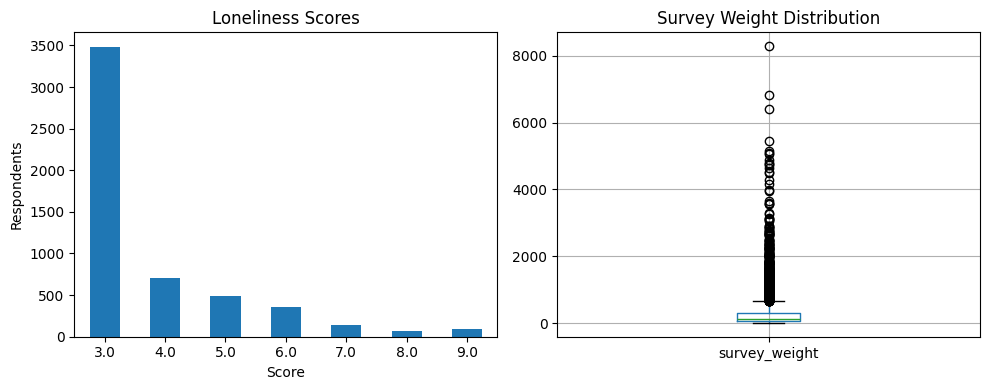

In [41]:
#Visualize the loneliness scores and survey weights
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

clean_df["loneliness_score"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Loneliness Scores"
)

axes[0].set_xlabel("Score")
axes[0].set_ylabel("Respondents")
axes[0].tick_params(axis="x", rotation=0)

clean_df.boxplot(column="survey_weight", ax=axes[1])
axes[1].set_title("Survey Weight Distribution")

plt.tight_layout()
plt.show()

The bar chart shows how common each valid score is. The boxplot flags unusually large weights for inspection, and they are not errors.

In [42]:
#inspecting extreme values

clean_df[["loneliness_score", "survey_weight"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]).round(2)

,loneliness_score,survey_weight
count,5326.00,5326.00
mean,3.78,282.67
std,1.35,488.90
min,3.00,5.01
25%,3.00,55.32
50%,3.00,132.47
75%,4.00,298.87
95%,7.00,1038.58
99%,9.00,2380.02
max,9.00,8290.48


In [43]:
#Inspect rare categorical responses
"""A rare transportation category may represent an important accessibility need. 
Low frequency alone does not justify deleting it."""
transport_counts = (
    clean_df["usual_transportation_mode"]
    .value_counts()
    .sort_index())

transport_counts

usual_transportation_mode
1.0    1016
2.0    3647
3.0      77
4.0     352
5.0      34
6.0      22
7.0     154
8.0      10
Name: count, dtype: int64

#### Outlier Treatment Decisions

- **High loneliness scores:** Our group want to retain scores within the valid range of 3–9 because they represent meaningful levels of loneliness.

- **Large survey weights:** We also want to retain positive weights because they reflect the sampling design. Capping them could distort population estimates.

- **Rare categorical responses:** We will also retain and flag uncommon categories. They may represent groups with distinct support needs, although small counts limit reliable comparisons.

#### Summary

No automatic outlier removal or capping is warranted. Valid extreme scores, survey weights, and rare categories will be preserved. Any other codes or values will be investigated further before changes are made.

## 6. Target variable exploration
Analyze the target variable and its distribution. For classification tasks check class
balance, for regression tasks check range, skewness, variance, and correlation analysis.
Find which variables may be most informative and which relationships appear weak or
noisy.

In [44]:
#Create the target using valid loneliness scores

"""
    0: Score 3–4, below the threshold.
    1: Score 5–9, meets the threshold.
"""
classification_df = clean_df[
    clean_df["loneliness_score"].notna()].copy()

classification_df["loneliness_status"] = (
    classification_df["loneliness_score"] >= 5).astype(int)

In [45]:
#Checking class balance

target = classification_df["loneliness_status"]

class_summary = pd.DataFrame({
    "Count": target.value_counts().sort_index(),
    "Percentage": target.value_counts(normalize=True).sort_index() * 100})

class_summary.round(2)

,Count,Percentage
loneliness_status,,
0,4187,78.61
1,1139,21.39


We can see 4,187 below threshold (78.61%) and 1,139 meeting the threshold (21.39%).

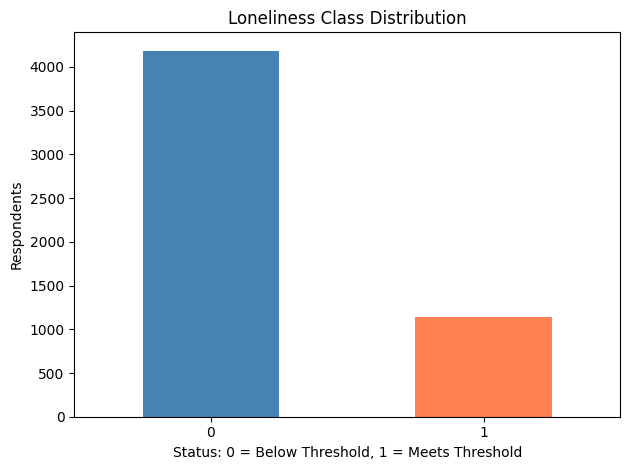

In [46]:
class_summary["Count"].plot(
    kind="bar",
    color=["steelblue", "coral"])

plt.title("Loneliness Class Distribution")
plt.xlabel("Status: 0 = Below Threshold, 1 = Meets Threshold")
plt.ylabel("Respondents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [47]:
#we have decided to reserve the test data before exploring the relationshios

from sklearn.model_selection import train_test_split

development_df, test_df = train_test_split(
    classification_df,
    test_size=0.20,
    random_state=42,
    stratify=classification_df["loneliness_status"])

In [48]:
#comparign candidate inputs with loneliness

comparison_tables = []

for column in input_features:
    summary = development_df.groupby(column)["loneliness_status"].agg(
        ["count", "sum", "mean"])

    summary = summary.reset_index()
    summary.columns = [
        "Category",
        "Respondents",
        "Lonely Respondents",
        "Loneliness Percentage"]

    summary["Feature"] = column
    summary["Loneliness Percentage"] *= 100

    comparison_tables.append(summary)

feature_comparison = pd.concat(
    comparison_tables,
    ignore_index=True)

feature_comparison = feature_comparison[
    ["Feature", "Category", "Respondents",
     "Lonely Respondents", "Loneliness Percentage"]]

feature_comparison.head(20).round(2)

,Feature,Category,Respondents,Lonely Respondents,Loneliness Percentage
0,sex_at_birth,1.0,1931,333,17.24
1,sex_at_birth,2.0,2329,578,24.82
2,marital_status_group,1.0,2369,324,13.68
3,marital_status_group,2.0,1873,582,31.07
4,household_size_group,1.0,1710,522,30.53
5,household_size_group,2.0,2541,384,15.11
6,province,10.0,99,17,17.17
7,province,11.0,160,33,20.62
8,province,12.0,166,33,19.88
9,province,13.0,110,18,16.36


For a binary target, its mean is the proportion meeting the threshold. Missing feature values are excluded from each comparison.

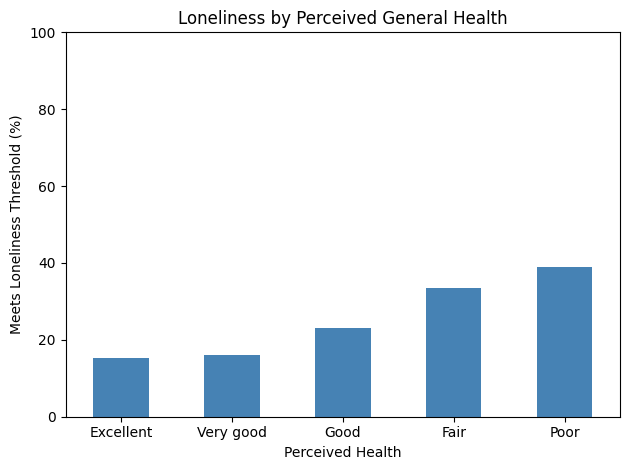

In [49]:
#Visualizing relationships
health_rates = (
    development_df.groupby("perceived_general_health")
    ["loneliness_status"].mean() * 100
)

health_rates = health_rates.rename(index={
    1: "Excellent",
    2: "Very good",
    3: "Good",
    4: "Fair",
    5: "Poor"})

health_rates.plot(kind="bar", color="steelblue")

plt.title("Loneliness by Perceived General Health")
plt.xlabel("Perceived Health")
plt.ylabel("Meets Loneliness Threshold (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

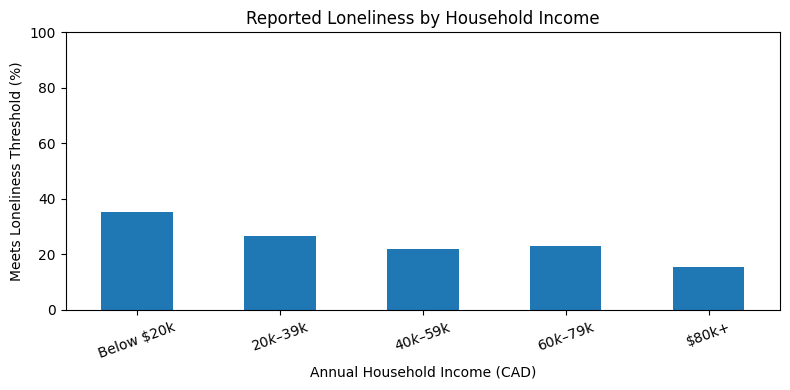

In [50]:
# Average loneliness score by household income
income_loneliness = (
    development_df.groupby("household_income_group")
    ["loneliness_status"].mean() * 100)

income_loneliness = income_loneliness.rename({
    1: "Below $20k",
    2: "$20k–$39k",
    3: "$40k–$59k",
    4: "$60k–$79k",
    5: "$80k+"
})

income_loneliness.plot(kind="bar", figsize=(8, 4))

plt.title("Reported Loneliness by Household Income")
plt.xlabel("Annual Household Income (CAD)")
plt.ylabel("Meets Loneliness Threshold (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

**Measuring the relationship in data using correlation, Reference - Week 6 data prep**

### Pearson Correlation Coefficient

$$
r =
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}
\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}
}
$$

Where:

- $r$ is the Pearson correlation coefficient.
- $x_i$ and $y_i$ are paired observations.
- $\bar{x}$ and $\bar{y}$ are their respective means.
- $n$ is the number of valid paired observations.

the coefficient ranges from $-1$ to $+1$:
- Positive values indicate a positive linear association.
- Negative values indicate a negative linear association.
- Values near zero indicate little linear association.

In [51]:
#Measuring the relationship in data using correlation
from scipy.stats import pearsonr

correlation_data = development_df[
    [
        "loneliness_score",
        "diabetes",
        "usual_pain_or_discomfort",
        "any_falls_past_12_months",
        "unmet_healthcare_need"
    ]].copy()

# Convert to 1 = condition/need present, 0 = absent.
correlation_data = correlation_data.replace({
    "diabetes": {1: 1, 2: 0},
    "usual_pain_or_discomfort": {1: 0, 2: 1},
    "any_falls_past_12_months": {1: 1, 2: 0},
    "unmet_healthcare_need": {1: 1, 2: 0}})

In [52]:
valid_data = correlation_data[
    ["diabetes", "loneliness_score"]
].dropna()
#Because diabetes is binary, this Pearson coefficient is equivalent to a point-biserial correlation.
correlation_coefficient, p_value = pearsonr(
    valid_data["diabetes"],
    valid_data["loneliness_score"])

print("Respondents:", len(valid_data))
print("Pearson correlation coefficient:", round(correlation_coefficient, 3))
print("P-value:", p_value)

Respondents: 4166
Pearson correlation coefficient: 0.019
P-value: 0.20969214113982185


In [53]:
#creating the correlation matrix
correlation_matrix = correlation_data.corr(method="pearson")
correlation_matrix.round(3)

,loneliness_score,diabetes,usual_pain_or_discomfort,any_falls_past_12_months,unmet_healthcare_need
loneliness_score,1.000,0.019,0.131,0.105,0.115
diabetes,0.019,1.000,0.058,0.036,0.021
usual_pain_or_discomfort,0.131,0.058,1.000,0.124,0.119
any_falls_past_12_months,0.105,0.036,0.124,1.000,0.098
unmet_healthcare_need,0.115,0.021,0.119,0.098,1.000


In [54]:
correlation_matrix["loneliness_score"].drop(
    "loneliness_score").round(3)

diabetes                    0.019
usual_pain_or_discomfort    0.131
any_falls_past_12_months    0.105
unmet_healthcare_need       0.115
Name: loneliness_score, dtype: float64

### Interpretation of the Correlation Results

All four indicators have positive but small correlations with loneliness scores. With 1 representing the presence of each condition or need:

- **Diabetes (r = 0.019):** Almost no association with loneliness scores.
- **Usual pain or discomfort (r = 0.131):** A weak positive association and the largest coefficient among these four indicators.
- **Falls in the past 12 months (r = 0.105):** A weak positive association.
- **Unmet healthcare need (r = 0.115):** A weak positive association.

Respondents reporting pain, falls, or unmet healthcare needs tend to have slightly higher loneliness scores. However, none of these indicators shows a strong individual association.

These are unweighted, unadjusted correlations, with missing responses excluded separately for each comparison. They do not mean causation or statistical significance. We also believe small correlations do not make a feature useless. But their predictive contribution will be assessed alongside other features during model validation.

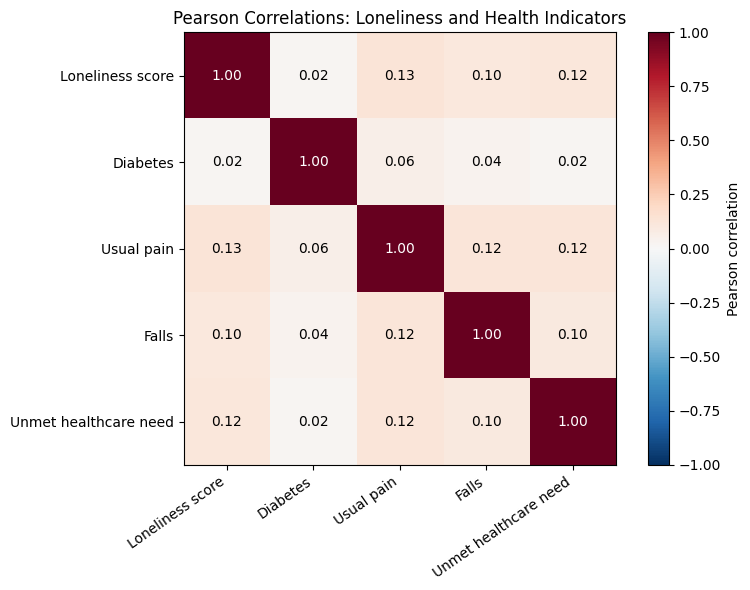

In [55]:
correlation_matrix = correlation_data.corr(method="pearson")

labels = [
    "Loneliness score",
    "Diabetes",
    "Usual pain",
    "Falls",
    "Unmet healthcare need"]

fig, ax = plt.subplots(figsize=(8, 6))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1)

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))

ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticklabels(labels)

# Display the correlation coefficient inside each square.
for row in range(len(labels)):
    for column in range(len(labels)):
        value = correlation_matrix.iloc[row, column]

        ax.text(
            column,
            row,
            f"{value:.2f}" if np.isfinite(value) else "N/A",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.5 else "black")

fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
ax.set_title("Pearson Correlations: Loneliness and Health Indicators")

plt.tight_layout()
plt.show()

### Pearson Correlation Heatmap Summary

**Reference - Week 6 data prep**

Loneliness scores have weak positive associations with usual pain (r = 0.13), unmet healthcare needs (r = 0.12), and falls (r = 0.10). Diabetes shows almost no association with loneliness (r = 0.02).

Correlations among the four health indicators are also small, ranging from 0.02 to 0.12. This suggests little pairwise linear redundancy among these selected indicators. The diagonal values of 1.00 represent each variable’s correlation with itself.

Overall, none of these indicators has a strong individual association with loneliness. Their usefulness for classification will be evaluated jointly during model validation.

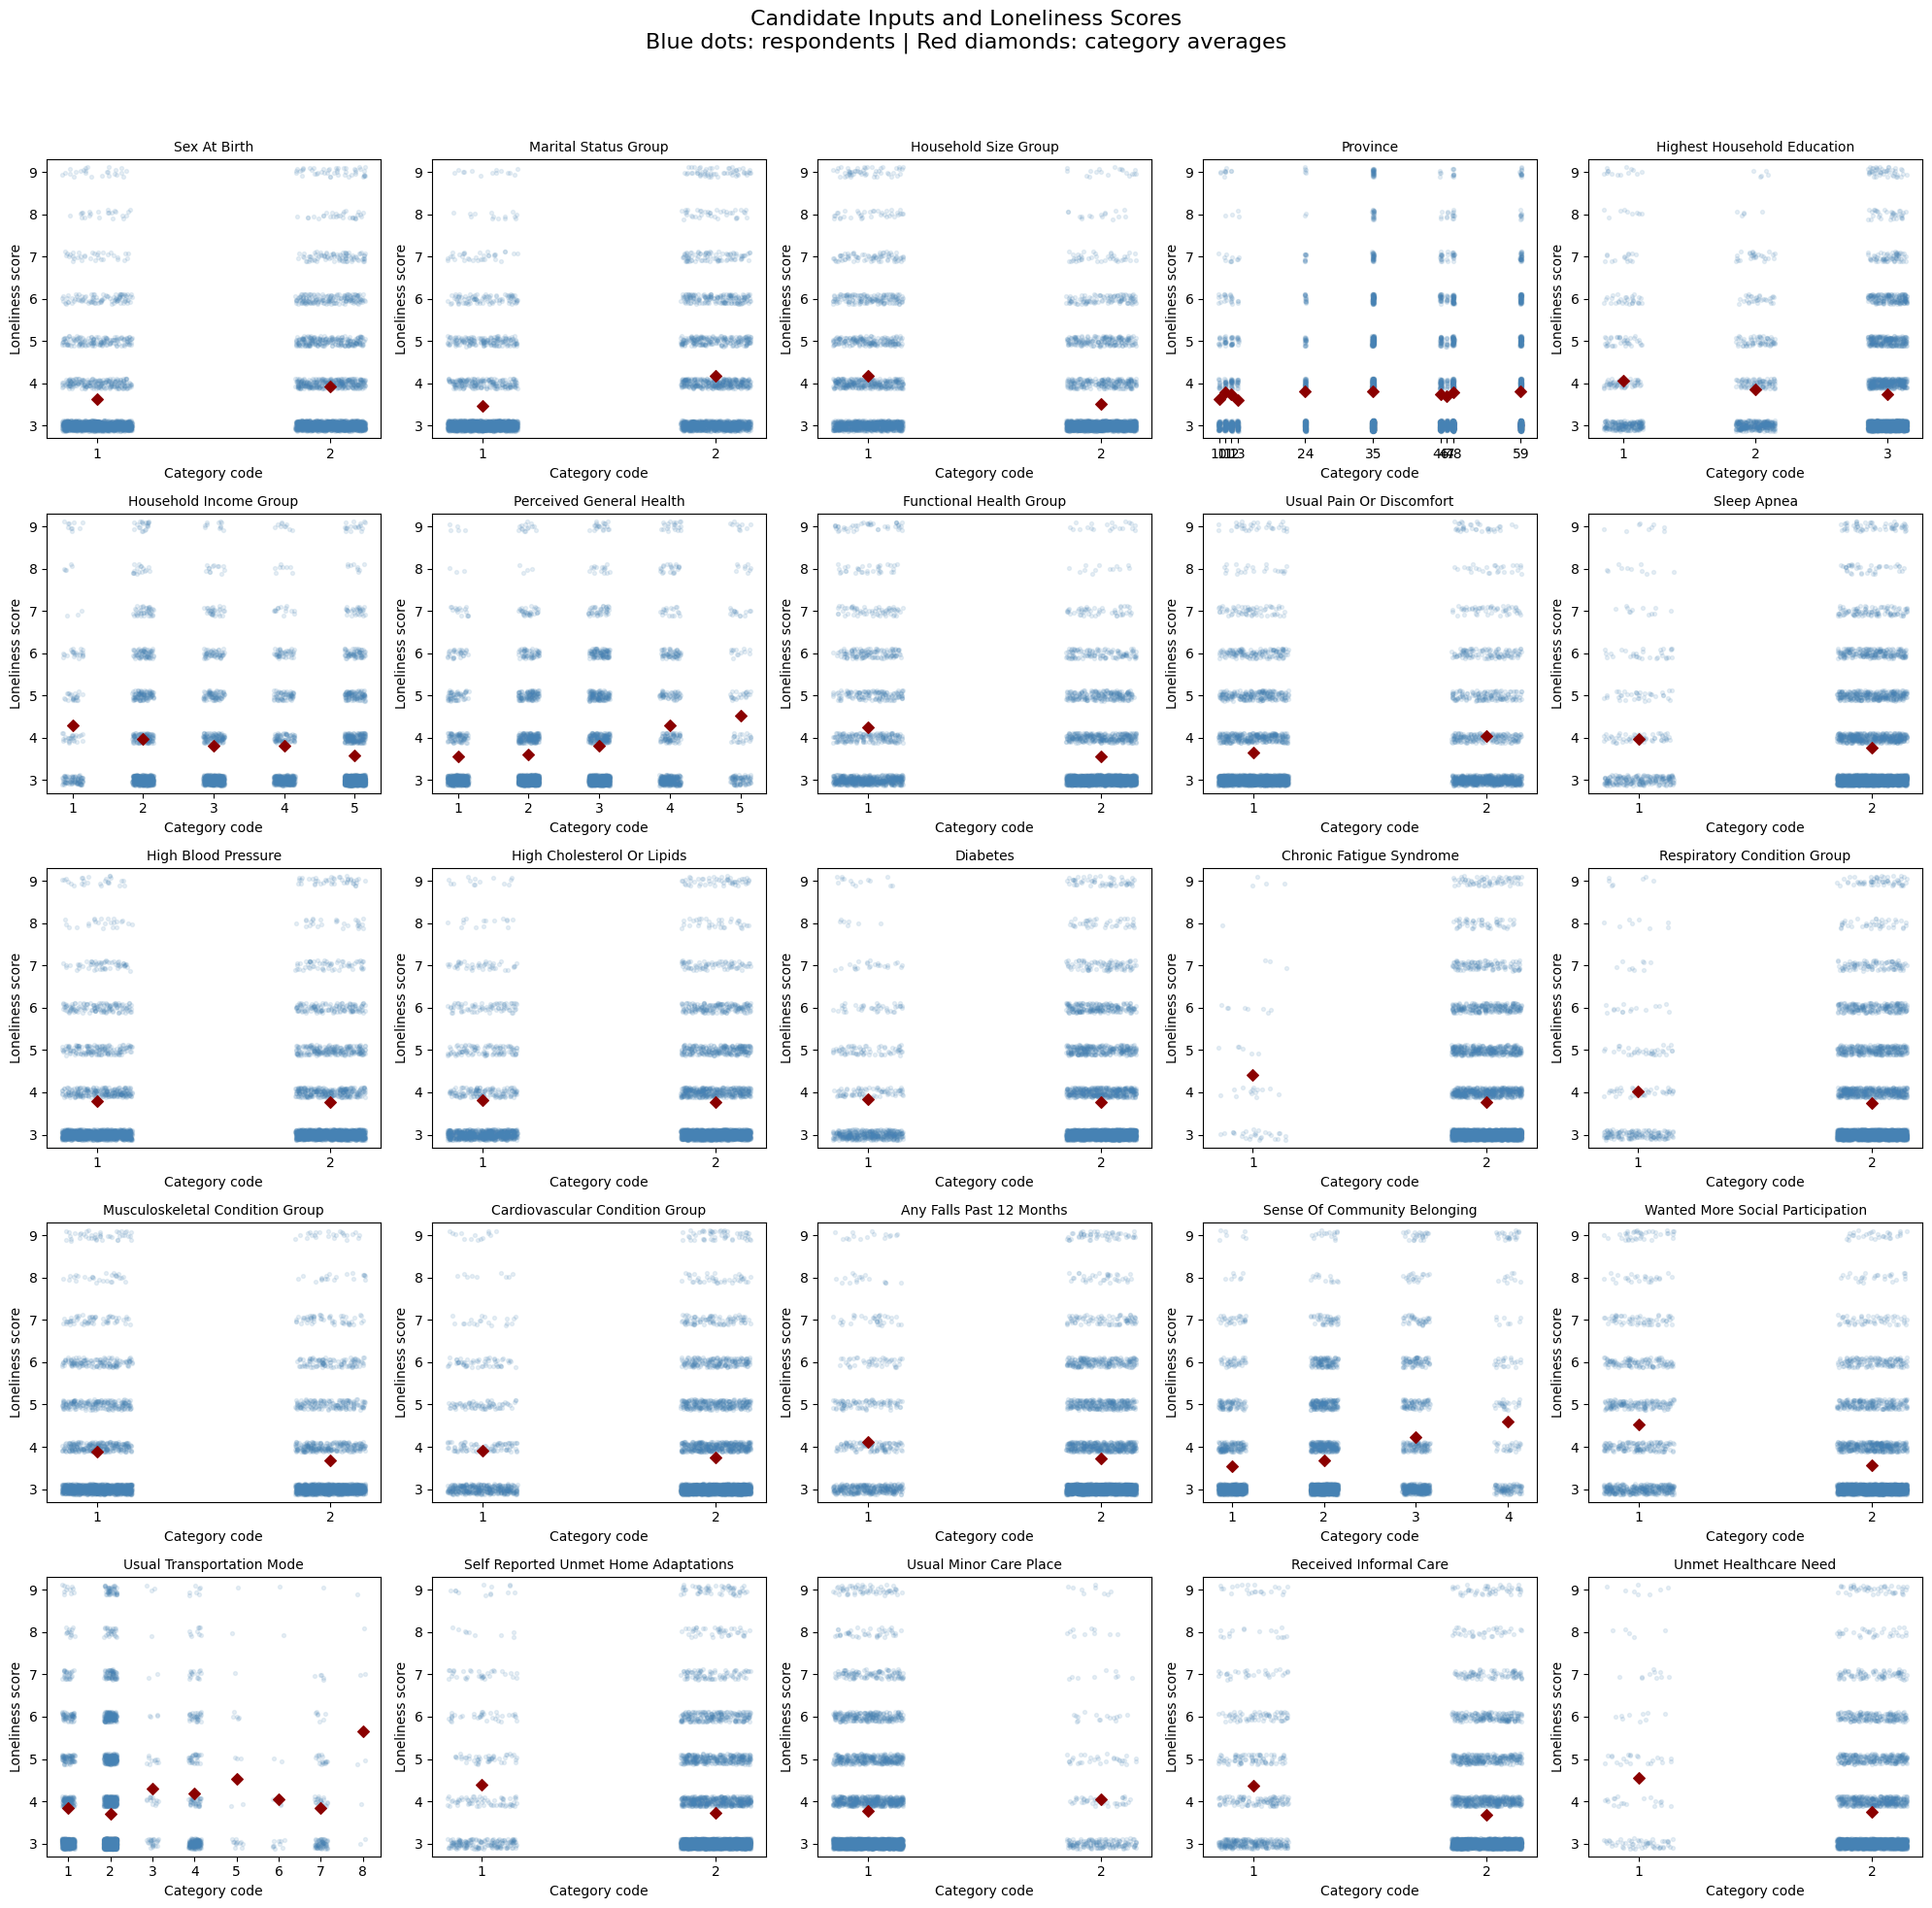

In [56]:
#scatter plot for candidate inputs and loneliness scores
rng = np.random.default_rng(42)

fig, axes = plt.subplots(5, 5, figsize=(20, 20))
axes = axes.flatten()

for ax, column in zip(axes, input_features):
    plot_data = development_df[
        [column, "loneliness_score"]].dropna()

    # Small offsets make overlapping observations visible.
    x = plot_data[column].to_numpy()
    y = plot_data["loneliness_score"].to_numpy()

    x_jitter = x + rng.uniform(-0.15, 0.15, len(x))
    y_jitter = y + rng.uniform(-0.12, 0.12, len(y))

    ax.scatter(
        x_jitter,
        y_jitter,
        alpha=0.12,
        s=8,
        color="steelblue")

    # Red diamonds show the average score in each category.
    category_means = plot_data.groupby(column)["loneliness_score"].mean()

    ax.scatter(
        category_means.index,
        category_means.values,
        color="darkred",
        marker="D",
        s=35,
        zorder=3)

    ax.set_title(column.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("Category code")
    ax.set_ylabel("Loneliness score")
    ax.set_xticks(sorted(plot_data[column].unique()))
    ax.set_yticks(range(3, 10))
    ax.set_ylim(2.7, 9.3)

plt.suptitle(
    "Candidate Inputs and Loneliness Scores\n"
    "Blue dots: respondents | Red diamonds: category averages",
    fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

- The above plots show that loneliness scores are near the lower end of the scale, although respondents within most categories span a wide range. Higher average loneliness is visible among those living alone,  poorer general, experiencing weaker community belonging, and for those who want more social participation. 
- Respondents reporting pain, falls, unmet healthcare or home needs, and informal care also show higher averages, while differences for diabetes, high blood pressure, and high cholesterol appear small.
- These patterns overall suggest useful predictors and overlapping support needs, but overlap between groups means no single feature clearly separates loneliness levels.

#### Summary

Candidate features are compared using loneliness percentages within each category. Large and consistent differences across adequately sized categories may suggest informative associations. Similar percentages suggest weaker unadjusted relationships. Differences based on few respondents or few positive cases may be noisy.
Missing responses are excluded separately for each feature, because comparison sample sizes can differ and we can see the proper insights.

## 7. Data preprocessing
Summarize EDA findings and finalize preprocessing and feature engineering to prepare
the dataset for the next phase of machine learning modeling.

In [57]:
#Separate predictors, target, and weights
X_development = development_df[input_features].copy()
y_development = development_df["loneliness_status"].copy()

X_test = test_df[input_features].copy()
y_test = test_df["loneliness_status"].copy()

development_weights = development_df["survey_weight"].copy()
test_weights = test_df["survey_weight"].copy()

The 25 candidate inputs exclude the loneliness score, IDs, survey weights, and administrative fields. This prevents direct target leakage.

In [58]:
#saving the healthcare valid skip indicator
X_development["unmet_healthcare_valid_skip"] = (
    development_df["unmet_healthcare_valid_skip"].astype(int))

X_test["unmet_healthcare_valid_skip"] = (
    test_df["unmet_healthcare_valid_skip"].astype(int))

This seperates a documented skip from other unavailable healthcare responses and it does not imply that the respondent had no unmet need. In the future steps, we decided to compare models with and without the healthcare need field and its indicator.

In [59]:
#Define missing-value handling and categorical encoding
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = Pipeline([
    (
        "missing_values",
        SimpleImputer(
            strategy="constant",
            fill_value=-1,
            keep_empty_features=True
        )
    ),
    ("category_encoding",OneHotEncoder(handle_unknown="ignore"))])

The selected predictors are categorical. We initially represent unavailable responses with a separate code, -1, and one-hot encode categories rather than assume equal spacing between their codes.

We will not fit this preprocessor yet in this assignment, but we will do it during modelling and combine it with the classifier in one pipeline and fit that pipeline inside each training fold.

In [60]:
#saving separate inputs for segmentation
segmentation_inputs = clean_df[input_features].copy()

In [61]:
#Final checks
print("Development inputs:", X_development.shape)
print("Test inputs:", X_test.shape)
print("Segmentation inputs:", segmentation_inputs.shape)

Development inputs: (4260, 26)
Test inputs: (1066, 26)
Segmentation inputs: (5326, 25)


### EDA Findings and Preprocessing Summary

- The study subgroup contains 5,871 respondents classified as immigrants or non-permanent residents. Out of these, 5,326 have an available loneliness outcome.

- The binary target has scores of 5 to 9 as meeting the loneliness threshold and scores of 3–4 as below it. Missing outcomes are not imputed.

- As we have seen that the target is imbalanced(21.39%) meeting the threshold. After this project I will select one of the three ways to handle imbalances. Future evaluation will include precision, recall, PR-AUC, and calibration alongside accuracy.

- Documented missing response codes have been converted to NaN. Healthcare valid skips are recorded separately from ordinary nonresponse.

- Valid extreme scores, rare categories, and survey weights are retained. No automatic capping or complete case deletion was applied on this dataset.

- In the initial model preparation we used a separate missing category and one-hot encoding. These choices will be assessed during development of data validation. Our group also belives that scaling is not required for this initial categorical representation.

- With the feature engineering process, our data consists of the binary target, the healthcare skip indicator, and categorical encoding.

- The loneliness score and its component questions are excluded from feature variables. IDs and survey weights are stored separately.

- The test sample remains reserved for final evaluation.

- This project also includes segmentation, association, and ranking as secondary tasks. So, from here, segmentation uses health and social characteristics without the target. Associations will remain exploratory. Group ranking will require criteria for loneliness, physical health needs, group size, and service capacity to rank which group of immigrants require social need or assistance. Hence, this step will be actioned later after the classification and segmentation tasks.